# Market experiment: the DFM and its conditioning on daily US equity returns

This notebook applies the pipeline of the [synthetic notebook](synthetic_dfm_conditional_benchmark.ipynb)
to market data, with the same dimensions: $d=500$ assets, $k=8$ factors and 2,500 training
observations. It trains DFM (MLP) and DFM (Gaussian + MLP), the two networks of the synthetic
notebook, and DFM (Regimes + MLP) on daily returns, freezes DFM (Regimes + MLP), and conditions it
on a loss of the equal-weight portfolio at the 5% and 1% levels. Three conditional models are
compared: CDG-ML and Refined CDG-ML, the two models of the synthetic notebook, and Refined CDG-ML
with a sequential Monte Carlo (SMC) correction.

Market returns have no exact law. The unconditional reference is a set of hold-out market
days. The conditional references are DFM rejection sampling, the law every conditional model
targets, and the hold-out market days in the event. The distances are those of the synthetic
notebook, with the market days in place of the exact law. [METHODS.md](METHODS.md) gives the
formulas of DFM (MLP), DFM (Gaussian + MLP), H, CDG-ML, Refined CDG-ML and the exact final step;
DFM (Regimes + MLP) and the SMC correction, which the synthetic notebook does not use, are
described in sections 2 and 3.

**Sources.** The DFM follows Chen et al. (2025); the terminal-event probability $H$, its Doob
guidance and CDG-ML follow Guo et al. (2026). The Gaussian + MLP and Regimes + MLP networks,
the five refinements and the exact final step are project adaptations. The SMC correction uses H as
twisting function (Wu et al., 2023).

## Configuration

`MODE="standard"` is the experiment; `MODE="smoke"` runs the same cells on 12 assets with
reduced budgets. Both use the DFM configuration `notebook_config`. Set
`SAVED_RUN` to the folder of a finished run to display its saved figures and tables without
computing anything.

| Setting | Smoke | Standard (default) |
| --- | ---: | ---: |
| Assets / factors | 12 / 8 | 500 / 8 |
| Training / validation / evaluation days | 2,048 / 512 / 512 | 2,500 / 750 / 3,000 |
| DFM epochs / hidden widths | 15 / (32, 32) | 1,500 / (64, 64) |
| Volatility regimes (factor × residual scales) | 4 × 3 | 4 × 3 |
| Integration steps | 100 | 400 |
| H train / validation / test trajectories | 2,048 / 1,024 / 1,024 | 40,000 / 2,000 / 2,000 |
| H epochs / hidden widths (validation every 157 optimizer steps) | 10 / (64, 64) | 50 / (64, 64) |
| Rows per conditional model | 512 | 3,000 |
| Accepted samples per DFM rejection stream (5% / 1%) | 128 / 64 | 1,000 / 1,000 |
| Proposal cap per DFM rejection stream (5% / 1%) | 25,600 / 64,000 | 200,000 / 1,000,000 |

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from dataclasses import asdict, replace
import os
import sys

import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "DFM.py").exists():
    raise RuntimeError("Run this notebook with the repository as working directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from market_benchmark.data import load_or_build_panel, split_panel
from market_benchmark.unconditional import run_market_unconditional, show_market_unconditional
from synthetic_benchmark.configuration import network_config, notebook_config
from synthetic_benchmark.reporting import DFM_LABELS, format_return

In [2]:
MODE = os.environ.get("MARKET_MODE", "standard")  # "smoke": 12 assets and reduced budgets.
# Folder of a finished run to display instead of computing; None computes a new run.
SAVED_RUN = os.environ.get("MARKET_SAVED_RUN")
# The panel is built from the raw prices on first use, then read from this file.
PANEL_PATH = Path(os.environ.get("MARKET_PANEL", ROOT / "data" / "processed" / "market_panel.npz"))
# "random": days assigned by a seeded permutation; "chronological": most recent days held out.
SPLIT, SPLIT_SEED = "random", 912
# The DFM recipe (synthetic_benchmark.configuration.DFM_RECIPE): per-asset standardization, PCA
# initialization, staged loading updates and log-spaced noising times with noise-variance weights, as in the
# synthetic notebook, and 8 validation noise draws. DFM (Regimes + MLP) has 4 factor and 3 residual scales.
CONFIG = notebook_config(MODE)
# DFM (Gaussian + MLP) and DFM (Regimes + MLP) keep their analytic part at its fit to the training days,
# and train only their MLP (synthetic_benchmark.configuration.NETWORK_SETTINGS).
# The three DFMs are trained on the same days; guidance runs on DFM (Regimes + MLP).
DFM_NETWORKS = ("mlp", "gaussian_mlp", "regime_mlp")
GUIDED_NETWORK = "regime_mlp"
OUTPUT = Path(SAVED_RUN) if SAVED_RUN else ROOT / "artifacts" / "market_benchmark" / (
    MODE + "_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
)
display(pd.DataFrame({DFM_LABELS[network]: asdict(network_config(CONFIG, network))
                      for network in DFM_NETWORKS})
        .drop(index=["dfm_regimes", "dfm_train_analytic", "dfm_ema_decay", "dfm_refit_knots"])
        .rename_axis("Effective DFM configuration"))

,DFM (MLP),DFM (Gaussian + MLP),DFM (Regimes + MLP)
Effective DFM configuration,,,
mode,standard,standard,standard
d,500,500,500
k,8,8,8
seeds,"(42,)","(42,)","(42,)"
cases,"(gaussian,)","(gaussian,)","(gaussian,)"
n_train,2500,2500,2500
n_val,750,750,750
n_eval,3000,3000,3000
dfm_epochs,1500,1500,1500


## 1. Build the market panel

**Data.** Daily adjusted closing prices from Yahoo Finance for the members of the S&P 500,
S&P 400 and S&P 600 indices as of October 2026, from December 1999 to December 2025. Returns
are simple daily returns, $R_{i,t}=P_{i,t}/P_{i,t-1}-1$.

**Assets.** The panel keeps the last 6,250 trading days and the assets with a price on every
one of them. Assets are taken from the S&P 500 first, then from the S&P 400, alphabetically, until $d=500$ are found.

**Days.** The days are split into 2,500 training, 750 validation and 3,000 evaluation days by
a seeded random permutation. The DFM treats daily returns as independent draws of one law, so
the three sets are exchangeable draws of the same period, as in the synthetic experiment. The
evaluation days never enter training or model selection. `SPLIT="chronological"` holds out
the most recent days instead, which also measures how the law changes in time.

**Event.** With $w=\mathbf 1/d$, the event is $w^\top R\le C_q$, where $C_q$ is the empirical
$q$-quantile of the equal-weight portfolio return over the training days, $q\in\{0.05,0.01\}$.

**Survivorship.** The panel contains today's index members with a complete history. It
describes the daily returns of companies that survived, not an investable historical universe.

In [3]:
panel = load_or_build_panel(PANEL_PATH)
if CONFIG.d < panel.d:
    panel = panel.first_assets(CONFIG.d)
split = split_panel(panel, CONFIG.n_train, CONFIG.n_val, CONFIG.n_eval, split=SPLIT, seed=SPLIT_SEED)

from market_benchmark.conditional import event_threshold

hold_out_portfolio = split.evaluation @ split.weights
display(pd.Series({
    "Assets": f"{panel.d:,}",
    "Days used": f"{split.info['first_day']} to {split.info['last_day']}",
    "Training / validation / evaluation days": f"{CONFIG.n_train:,} / {CONFIG.n_val:,} / {CONFIG.n_eval:,}",
    "Split": SPLIT,
    "5% threshold of the portfolio return (training days)": format_return(event_threshold(split, 0.05)),
    "1% threshold of the portfolio return (training days)": format_return(event_threshold(split, 0.01)),
    "Hold-out days in the 5% / 1% event": " / ".join(
        f"{int((hold_out_portfolio <= event_threshold(split, q)).sum()):,}" for q in (0.05, 0.01)),
}, name="Market panel").to_frame())

,Market panel
Assets,500
Days used,2001-02-26 to 2025-12-31
Training / validation / evaluation days,"2,500 / 750 / 3,000"
Split,random
5% threshold of the portfolio return (training days),-1.76%
1% threshold of the portfolio return (training days),-3.32%
Hold-out days in the 5% / 1% event,187 / 46


## 2. Train and sample the unconditional DFM

DFM (MLP), DFM (Gaussian + MLP) and DFM (Regimes + MLP) are trained on the training days with
per-asset standardization, PCA initialization, staged loading updates and log-time,
variance-weighted score matching, as in the synthetic notebook (section 2 there). The validation
days select the epoch. Each DFM then generates as many returns as there are evaluation days.

**Why DFM (Regimes + MLP).** Market days share a volatility level: on a given day, factors and
residuals are large together, which makes the portfolio and every asset heavy-tailed. The
Gaussian part of DFM (Gaussian + MLP) has one fixed variance per asset and cannot represent
this. DFM (Regimes + MLP) can: it replaces the Gaussian part by a scale mixture of Gaussians, in
which factors and residuals share a scale regime $(j,l)$ drawn from a probability table $\pi$,

$$
F\mid j\sim N(m_f,a_j^2S_f),\qquad \varepsilon\mid l\sim N(0,b_l^2\operatorname{diag}(c)),
$$

with 4 factor scales $a_j$ and 3 residual scales $b_l$, normalized so that
$\sum_{j,l}\pi_{jl}a_j^2=\sum_{j,l}\pi_{jl}b_l^2=1$: $VS_fV^\top+\operatorname{diag}(c)$ stays the
covariance. The noised law is a mixture of Gaussians, so the analytic part of the score is exact:
the average of the Gaussian scores of the regimes, with $a_j^2S_f$ and $b_l^2c$ in place of $S_f$
and $c$, weighted by their posterior probabilities. The MLP correction is added as in
DFM (Gaussian + MLP) and also reads the posterior mean of $\log b_l$, the volatility level. The
scales and the table are fitted to the training days by maximum likelihood, together with the
Gaussian part, with a penalty that keeps the second moments of the training days.

**Fixed analytic part.** Score matching barely constrains the factor variances: the part of the
loss inside $\operatorname{span}(V)$ is a few percent of it. DFM (Gaussian + MLP) and
DFM (Regimes + MLP) therefore keep $V$, $c$ and the rest of their analytic part (the Gaussian
factor law and, with regimes, the scales and the table) at their fit to the training days, and
train only their MLP. In the synthetic notebook, DFM (Gaussian + MLP) trains all its parameters.
DFM (MLP) trains all its parameters, as in Chen et al. (2025).

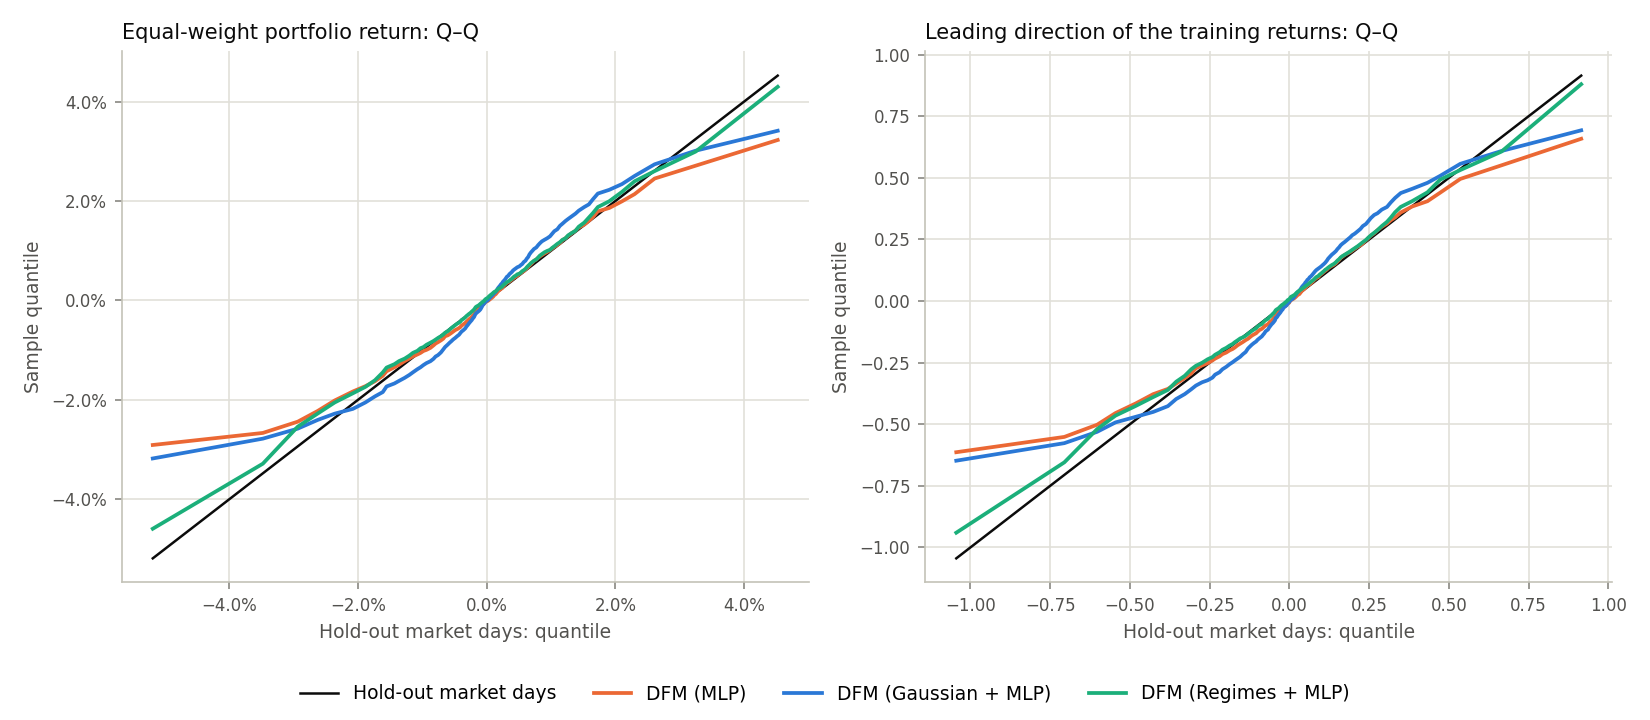

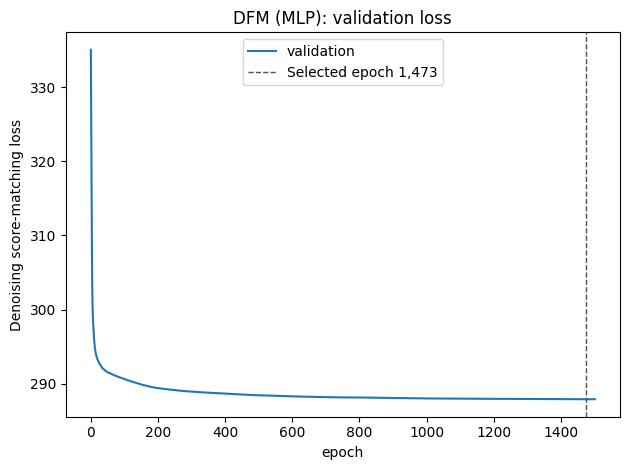

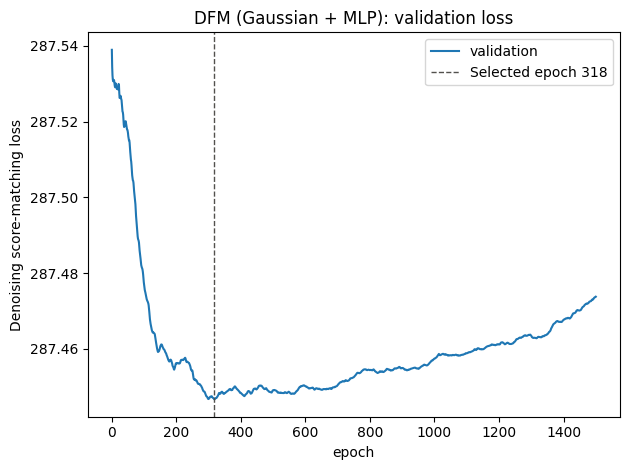

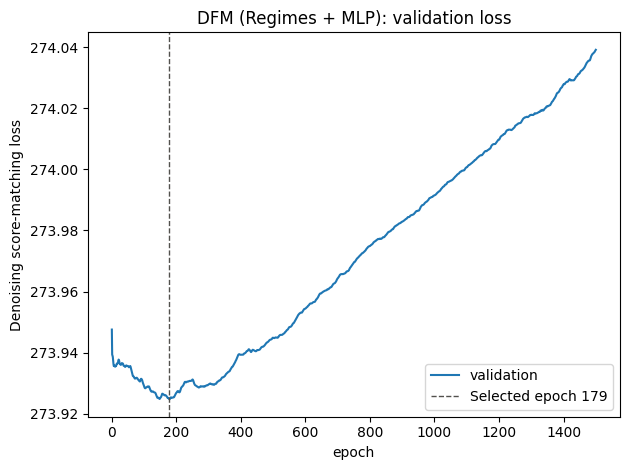

**Unconditional returns: values next to the hold-out market days.**

,Hold-out market days,DFM (MLP),DFM (Gaussian + MLP),DFM (Regimes + MLP)
Mean portfolio return,0.05%,0.05%,0.08%,0.10%
Portfolio volatility,1.32%,1.11%,1.30%,1.24%
5% quantile of the portfolio return,-1.98%,-1.78%,-2.12%,-1.83%
1% quantile of the portfolio return,-3.78%,-2.76%,-2.93%,-3.62%
Excess kurtosis of the portfolio return,9.05,0.91,0.03,5.96


**Unconditional returns: distances to the hold-out market days (lower is better).** Each source uses 3,000 rows. The noise level is the 95% quantile of the same distance between two bootstrap samples of 3,000 days drawn from every market day (training, validation and hold-out): a value at or below it cannot be told apart from the sampling variation between two market samples.

,DFM (MLP),DFM (Gaussian + MLP),DFM (Regimes + MLP),"Noise level (95%, n=3,000)",DFM (Regimes + MLP) within noise?
Portfolio: KS distance to the hold-out days,0.0413,0.0747,0.0280,0.0317,yes
Joint law: sliced W1 distance to the hold-out days,0.002080,0.002501,0.001159,0.000920,no
Covariance: relative error to the hold-out covariance,0.328,0.140,0.189,0.187,no


In [4]:
if not SAVED_RUN:
    run_market_unconditional(CONFIG, split, OUTPUT, networks=DFM_NETWORKS, verdict=GUIDED_NETWORK)
dfm_values, dfm_distances = show_market_unconditional(OUTPUT, networks=DFM_NETWORKS)

## 3. The conditional models

DFM (Regimes + MLP) is frozen. CDG-ML and Refined CDG-ML are trained and sampled on it as in the
synthetic notebook (sections 3 to 5 there): both H models are trained on the same unguided
trajectories of the frozen DFM, and every sampler starts from the H-tilted initial law and ends
with the exact final step. Refined CDG-ML + SMC corrects the guided steps of Refined CDG-ML by
sequential Monte Carlo, which the synthetic notebook does not use.

| Model | H | Sampler |
| --- | --- | --- |
| CDG-ML | Guo et al. (2026), no refinement | Guided Euler steps, exact final step |
| Refined CDG-ML | The five refinements | Guided Euler steps, exact final step |
| Refined CDG-ML + SMC | H of Refined CDG-ML | Guided steps corrected by SMC, exact final step |

**SMC correction.** The rows of Refined CDG-ML + SMC are the particles of one system that follows
the guided sampler of Refined CDG-ML, with H as twisting function (Wu et al., 2023). At each
guided step, the weight of a particle is multiplied by the ratio of H at its new and previous
states and by the ratio of the unguided to the guided density of the step; at the last guided
step, the probability $p_{\rm last}$ that the exact final step lands in the event
([METHODS.md](METHODS.md)) takes the place of H. When the effective sample size falls below half
the particles, they are resampled in proportion to their weights by systematic resampling
(Kitagawa, 1996), and once more before the exact final step, so the rows are equally weighted.
Rows that descend from the same path are not independent.

**H no longer reduces the dimension exactly.** On the Gaussian population, returns are factors
plus residuals of fixed variances, and the score has the form $\alpha_sD_sVg(V^\top D_sr,s)-D_sr$
with a single $D_s$ (section 2 of the synthetic notebook). The probability of the event given the
whole state $X_t$ then depends on it only through the $k+1$ coordinates $Y_t=(Z_t,U_t)$, and H
loses nothing by reading $Y_t$ instead of the $d$ coordinates of $X_t$. Changing the DFM breaks
this reduction. The scale mixture of DFM (Regimes + MLP) gives each residual scale $b_l$ its own
matrix $D_{s,l}=\operatorname{diag}(h_s+\alpha_s^2b_l^2c_i)^{-1}$. Without the MLP correction, the
probability of the event given $X_t$ is the average of the Gaussian-case probabilities of the
regimes, weighted by their posterior probabilities. Each regime's probability reads its own
coordinates $Y_{t,l}$, built as $Y_t$ with $D_{s,l}$ in place of $D_s$, and the posterior
probabilities also depend on $X_t^\top D_{s,l}X_t$, the size of the state over all assets, that
is its volatility level. The exact probability is a function of these $3(k+2)$ numbers, one block
per residual scale, not of the $k+1$ of $Y_t$.

**What we do.** H keeps the inputs $Y_t$ of the Gaussian population. It then estimates the
probability of the event given $Y_t$ only, averaged over the volatility levels of the unguided
states with the same $Y_t$, and its guidance is approximate even for a perfectly trained H. Two
parts of the samplers do not rely on H: the exact final step places every row in the event, and
the SMC correction reweights the guided paths so that, as the number of particles grows, its rows
follow the law DFM rejection samples. A poor H only makes the weights more uneven, and the rows
then repeat fewer, correlated paths.

## 4. Evaluate the conditional returns

| Source | How it is produced |
| --- | --- |
| Hold-out market days in the event | Evaluation days with $w^\top R\le C_q$ |
| DFM rejection sampling | Unguided draws of the frozen DFM on the same grid, keeping $w^\top R\le C_q$ |
| The three conditional models | Section 3 |

| Comparison | What it assesses |
| --- | --- |
| DFM rejection vs hold-out market days in the event | Error of the DFM's own conditional law |
| Conditional model vs DFM rejection | Error of the conditioning: learned H, guided integration |
| Conditional model vs hold-out market days in the event | Combined error |
| DFM rejection vs independent DFM rejection | Sampling variation at the same sample size |



In [5]:
from market_benchmark.conditional import conditional_folder, run_market_conditional, show_market_conditional
from synthetic_benchmark.configuration import rejection_assessment
from synthetic_benchmark.reporting import MODELS, conditioning_error_table, readable_conditioning_error

# Events computed and displayed; "0.05" skips the 1% event, whose DFM rejection streams are long,
# and "none" every event.
TAILS = tuple(float(tail) for tail in os.environ.get("MARKET_TAILS", "0.05,0.01").split(",")
              if tail.strip() not in ("", "none"))
# Guidance targets the frozen DFM (Regimes + MLP); the run folders carry the network's name.
GUIDED_CONFIG = network_config(CONFIG, GUIDED_NETWORK)
# Models drawn in the figure, beside DFM rejection and the hold-out market days; the tables list every model.
PLOT_SOURCES = ("refined_exact", "refined_smc")
# The H recipe of the synthetic notebook: 40k trajectories, 50 epochs, validation every 157 optimizer steps.
H_RECIPE = dict(
    plot_sources=PLOT_SOURCES,
    n_train=2_048 if CONFIG.mode == "smoke" else 40_000,
    n_validation=1_024 if CONFIG.mode == "smoke" else 2_000,
    n_test=1_024 if CONFIG.mode == "smoke" else 2_000,
    epochs=10 if CONFIG.mode == "smoke" else 50,
    validation_interval_steps=157,
    widths=(64, 64),
    initialization_seed=2027,
    lr=1e-3,
    batch_size=64,
    path_batch_size=256,
    train_seeds={"train": 32001, "validation": 32002, "test": 32003, "shuffle": 32004},
    n_samples=CONFIG.n_eval,
    sample_batch_size=256,
    guided_seed=42001,
    smc_seed=42011,
    smc_ess_threshold=0.5,
)
# Accepted rows per DFM rejection stream, by event. A DFM may put less mass than the market in the
# far tail, so a stream may draw up to 10 times the proposals expected at the nominal probability.
REJECTION_ROWS = {0.05: 128, 0.01: 64} if CONFIG.mode == "smoke" else {0.05: 1_000, 0.01: 1_000}
ASSESSMENT = dict(
    cap_factor=10,
    rejection_batch_size=2_048,
    rejection_seed=42003, rejection_reference_seed=42004, truth_reference_seed=42005,
    projection_seed=42006, matching_seed=42007, projections=64, noise_seed=42009,
)

### The 5% event

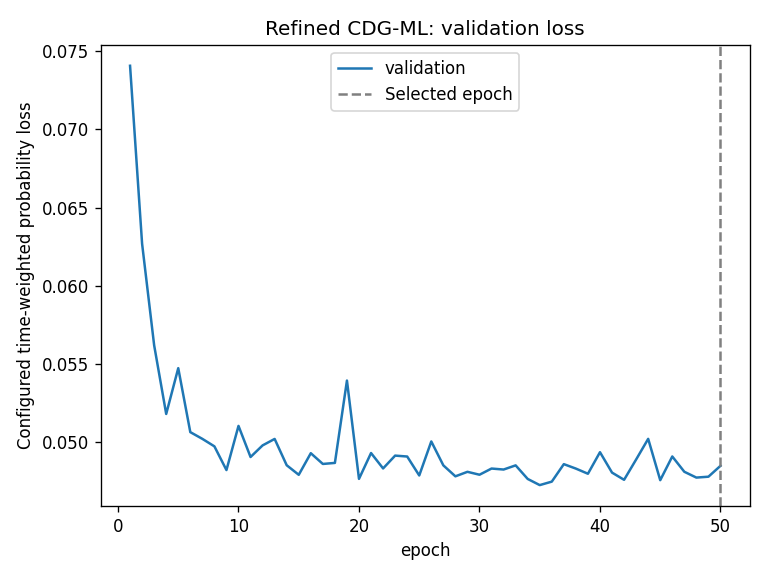

,Refined CDG-ML,CDG-ML
Held-out Brier loss,0.0240,0.0249
Constant-probability Brier loss,0.0475,0.0475
First-layer Tanh saturation,0.1900,0.3413
Last-step probability RMSE,0.0465,0.1595
Last-step gradient relative RMSE,0.8129,0.9953
Last-step gradient cosine,0.9602,0.6491
Selected epoch,50,48
Selected optimizer step,"31,086","29,987"


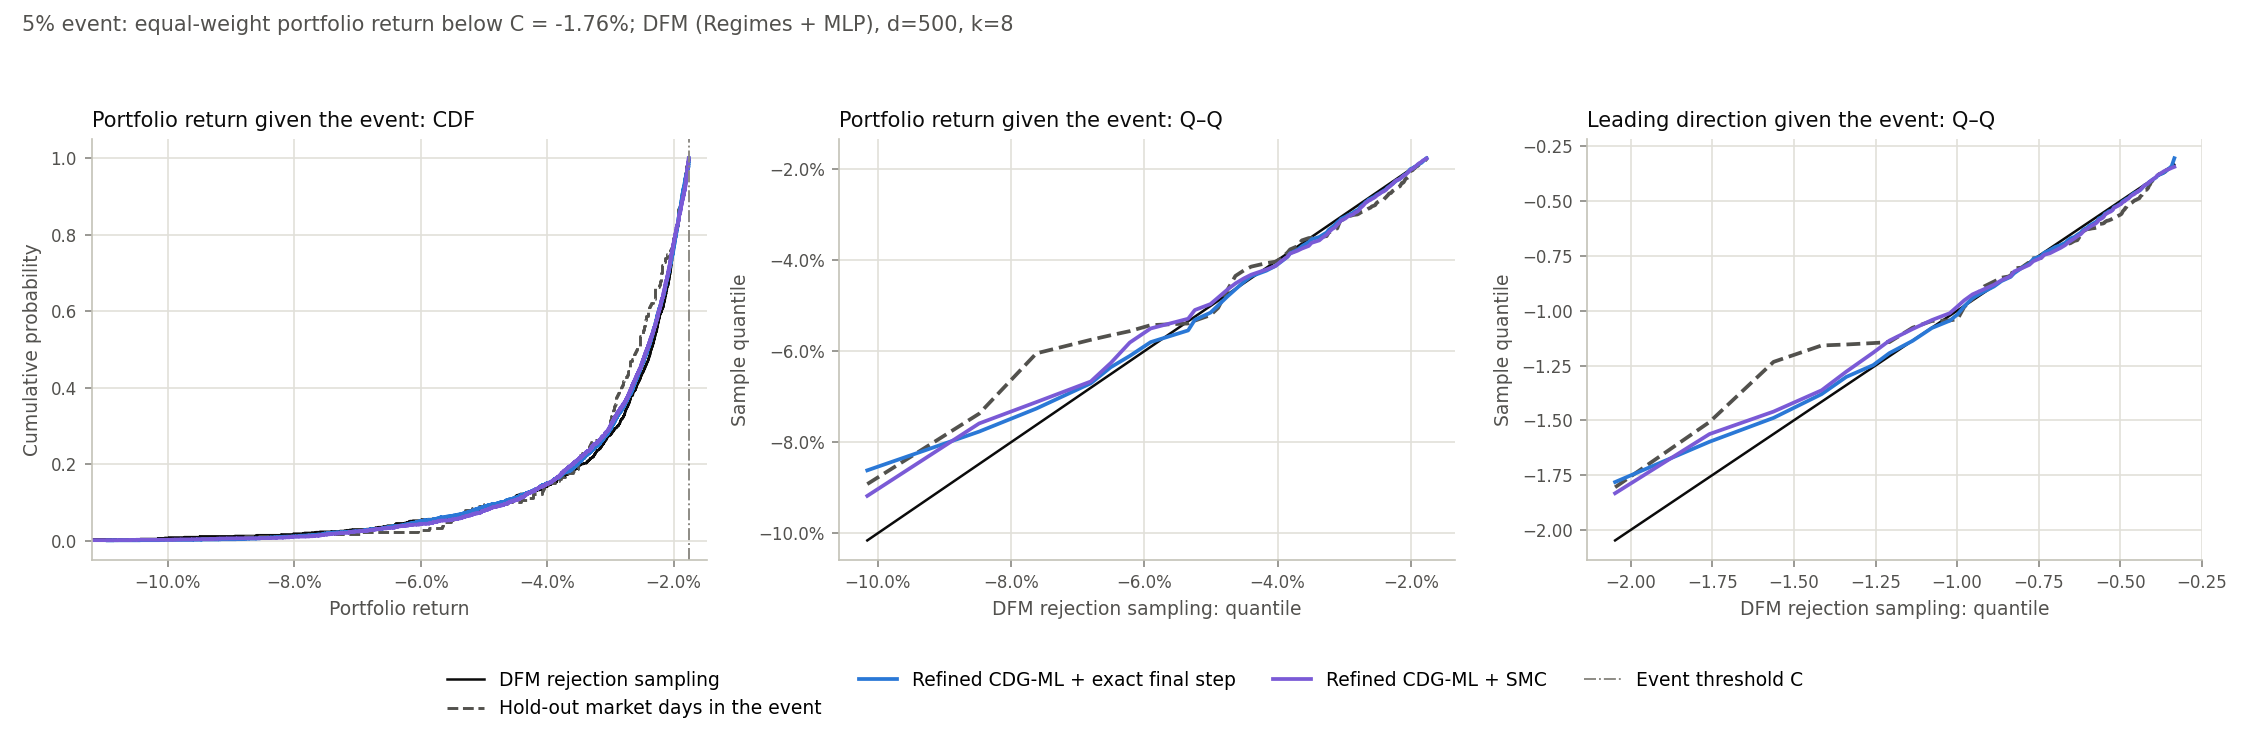

**5% event: values next to the hold-out market days in the event.**

,Hold-out market days in the event,DFM rejection,CDG-ML,Refined CDG-ML,Refined CDG-ML + SMC
Expected shortfall: mean return given the event,-2.95%,-2.90%,-3.02%,-2.91%,-2.90%
Volatility given the event,1.31%,1.48%,1.58%,1.36%,1.34%
Rows in the event,100.0%,100.0%,100.0%,100.0%,100.0%
Rows,187,"1,000","3,000","3,000","3,000"
Event frequency without conditioning,6.23%,5.41%,—,—,—


**5% event: distances to the hold-out market days in the event (lower is better).** Each source uses 187 rows. The noise level is the 95% quantile of the same distance between two bootstrap samples of 187 days drawn from every market day in the event (training, validation and hold-out): a value at or below it cannot be told apart from the sampling variation between two market samples.

,DFM rejection,CDG-ML,Refined CDG-ML,Refined CDG-ML + SMC,"Noise level (95%, n=187)",Refined CDG-ML + SMC within noise?
Portfolio: KS distance to the hold-out days in the event,0.144,0.080,0.123,0.123,0.134,yes
Joint law: sliced W1 distance to the hold-out days in the event,0.00487,0.00451,0.00458,0.00457,0.00445,no
Covariance: relative error to the hold-out covariance in the event,0.794,0.918,0.644,0.695,0.959,yes


**Sequential Monte Carlo correction.** The particles follow the guided sampler and are resampled in proportion to their weights when the effective sample size falls below the threshold, and once more before the exact final step. The rows are then equally weighted and, as the number of particles grows, follow the law DFM rejection samples. Rows that descend from the same path are not independent: the distinct shares say how many separate paths remain.

,DFM rejection,Refined CDG-ML + SMC
Resampling times,—,2
Lowest effective sample size (share of particles),—,49.4%
Effective sample size before the last resampling,—,59.3%
Distinct paths kept by the last resampling,—,90.5%
Distinct starting points,—,70.0%
DFM event frequency,5.41%,5.17%


In [6]:
if 0.05 in TAILS:
    if not SAVED_RUN:
        run_market_conditional(
            GUIDED_CONFIG, split, OUTPUT, tail=0.05, label=GUIDED_NETWORK, **H_RECIPE,
            assessment_settings=rejection_assessment(0.05, REJECTION_ROWS[0.05], **ASSESSMENT),
        )
    conditional_5 = show_market_conditional(OUTPUT, 0.05, GUIDED_NETWORK)

### The 1% event

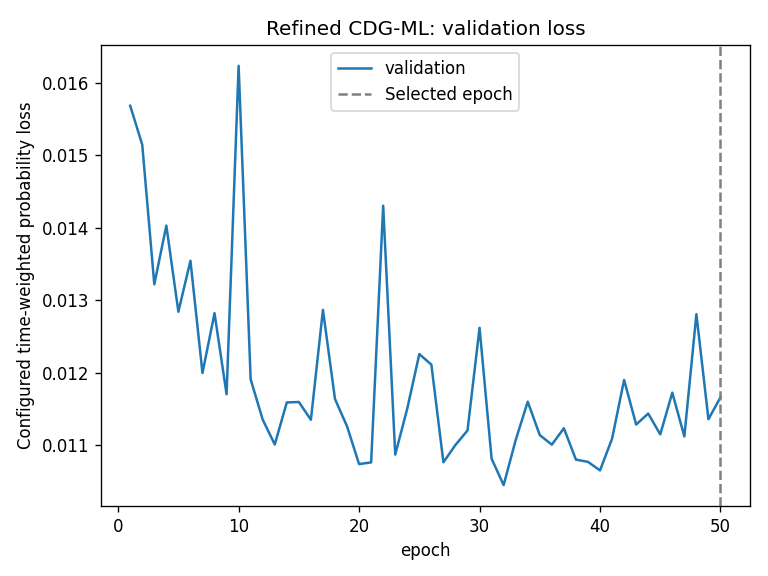

,Refined CDG-ML,CDG-ML
Held-out Brier loss,0.0049,0.0055
Constant-probability Brier loss,0.0114,0.0114
First-layer Tanh saturation,0.2269,0.3448
Last-step probability RMSE,0.0230,0.0741
Last-step gradient relative RMSE,—,—
Last-step gradient cosine,—,—
Selected epoch,50,39
Selected optimizer step,"31,086","24,178"


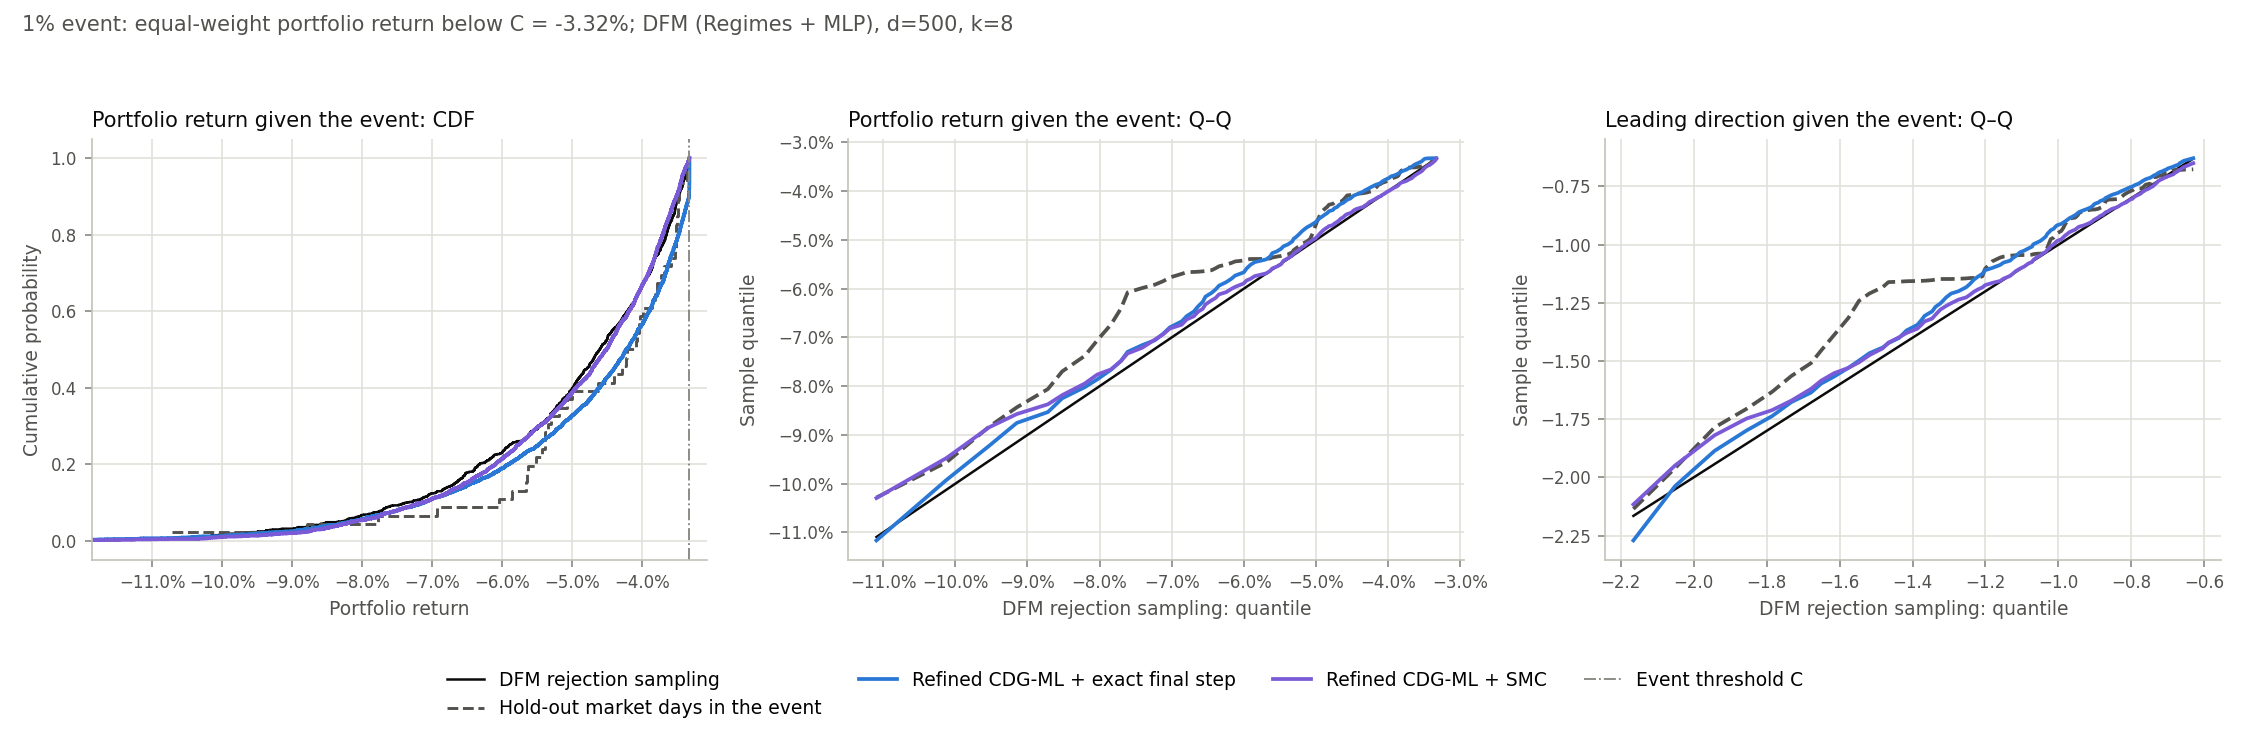

**1% event: values next to the hold-out market days in the event.**

,Hold-out market days in the event,DFM rejection,CDG-ML,Refined CDG-ML,Refined CDG-ML + SMC
Expected shortfall: mean return given the event,-4.71%,-5.05%,-4.92%,-4.79%,-4.98%
Volatility given the event,1.52%,1.62%,1.73%,1.61%,1.52%
Rows in the event,100.0%,100.0%,100.0%,100.0%,100.0%
Rows,46,"1,000","3,000","3,000","3,000"
Event frequency without conditioning,1.53%,1.18%,—,—,—


**1% event: distances to the hold-out market days in the event (lower is better).** Each source uses 46 rows. The noise level is the 95% quantile of the same distance between two bootstrap samples of 46 days drawn from every market day in the event (training, validation and hold-out): a value at or below it cannot be told apart from the sampling variation between two market samples.

,DFM rejection,CDG-ML,Refined CDG-ML,Refined CDG-ML + SMC,"Noise level (95%, n=46)",Refined CDG-ML + SMC within noise?
Portfolio: KS distance to the hold-out days in the event,0.217,0.348,0.174,0.217,0.262,yes
Joint law: sliced W1 distance to the hold-out days in the event,0.0124,0.0113,0.0132,0.0112,0.0115,yes
Covariance: relative error to the hold-out covariance in the event,0.976,1.017,0.908,1.040,1.213,yes


**Sequential Monte Carlo correction.** The particles follow the guided sampler and are resampled in proportion to their weights when the effective sample size falls below the threshold, and once more before the exact final step. The rows are then equally weighted and, as the number of particles grows, follow the law DFM rejection samples. Rows that descend from the same path are not independent: the distinct shares say how many separate paths remain.

,DFM rejection,Refined CDG-ML + SMC
Resampling times,—,2
Lowest effective sample size (share of particles),—,50.0%
Effective sample size before the last resampling,—,69.0%
Distinct paths kept by the last resampling,—,88.1%
Distinct starting points,—,62.7%
DFM event frequency,1.18%,1.18%


In [7]:
if 0.01 in TAILS:
    if not SAVED_RUN:
        run_market_conditional(
            GUIDED_CONFIG, split, OUTPUT, tail=0.01, label=GUIDED_NETWORK, **H_RECIPE,
            assessment_settings=rejection_assessment(0.01, REJECTION_ROWS[0.01], **ASSESSMENT),
        )
    conditional_1 = show_market_conditional(OUTPUT, 0.01, GUIDED_NETWORK)

### Conditioning error of every model

In [8]:
# Read back the matched comparisons saved for each event: nothing is trained or sampled again.
if TAILS:
    saved_comparisons = {tail: pd.read_csv(OUTPUT / conditional_folder(tail, GUIDED_NETWORK) / "comparisons.csv")
                         for tail in TAILS}
    # Every model of this notebook, Refined CDG-ML + SMC included; the synthetic notebook has two.
    conditioning_error = conditioning_error_table(saved_comparisons, models=MODELS)
    conditioning_error.to_csv(OUTPUT / "conditioning_error.csv")
    conditioning_note, conditioning_display = readable_conditioning_error(conditioning_error)
    display(Markdown(conditioning_note), conditioning_display)

**Conditioning error: distances to DFM rejection (lower is better).** Each distance compares 1,000 matched rows of a model with the DFM rejection sample. The rejection-vs-rejection reference is the same distance between two independent DFM rejection streams of that size: one Monte Carlo draw, which describes sampling variation; it is not a 95% noise level.

CDG-ML Refined CDG-ML Refined CDG-ML + SMC  \
Event    Metric                                                               
5% event Portfolio KS distance   0.0600         0.0320               0.0620   
         Portfolio W1 distance  0.00172       0.000627              0.00147   
         Sliced W1 distance     0.00229        0.00185              0.00188   
1% event Portfolio KS distance    0.201          0.123               0.0370   
         Portfolio W1 distance  0.00166        0.00280              0.00115   
         Sliced W1 distance     0.00321        0.00325              0.00241   

                               Rejection-vs-rejection reference  
Event    Metric                                                  
5% event Portfolio KS distance                           0.0270  
         Portfolio W1 distance                         0.000540  
         Sliced W1 distance                             0.00164  
1% event Portfolio KS distance                           0.0400  
         Portfolio W1 distance                         0.000625  
         Sliced W1 distance                             0.00193